In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## Задание 2.1

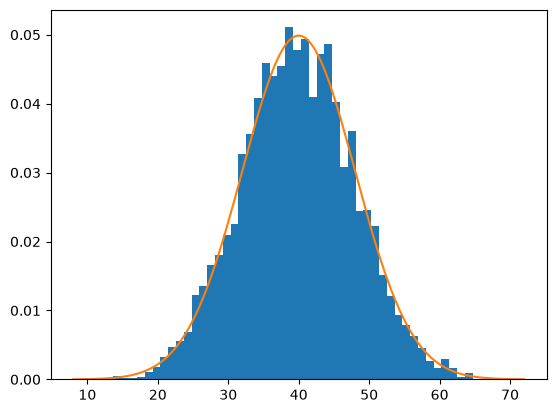

In [2]:
mu, sigma = 40, 8
sample = np.random.normal(mu, sigma, size=5000)
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.hist(sample, bins=50, density=True)
plt.plot(x, stats.norm.pdf(x, mu, sigma))
plt.show()

In [3]:
print(f"sample mean = {round(sample.mean(), 4)}")
print(f"sample std = {round(sample.std(), 4)}")

sample mean = 39.8736
sample std = 7.9711


Выборочные среднее и ско сошлись с тем, что мы задавали.

## Задание 2.2

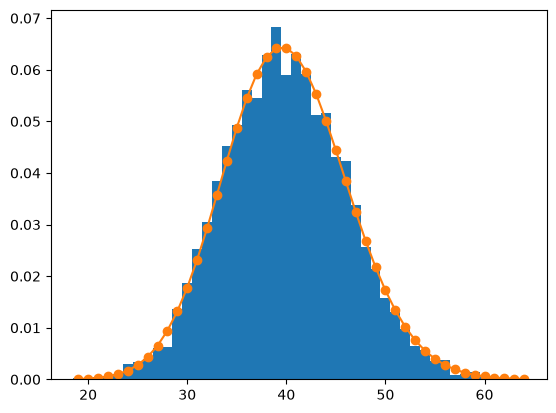

In [4]:
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000)
k = np.arange(sample.min(), sample.max() + 1)

plt.hist(sample, bins=k - 0.5, density=True)
plt.plot(k, stats.binom.pmf(k, n, p), 'o-')
plt.show()

In [5]:
print(f"real mean = {round(n * p, 4)}")
print(f"real std = {round(np.sqrt(n * p * (1 - p)), 4)}")
print(f"sample mean = {round(sample.mean(), 4)}")
print(f"sample std = {round(sample.std(), 4)}")

real mean = 40.0
real std = 6.1968
sample mean = 39.9122
sample std = 6.198


По выборке среднее и ско полностью совпали с теоретическими.

## Задание 2.3

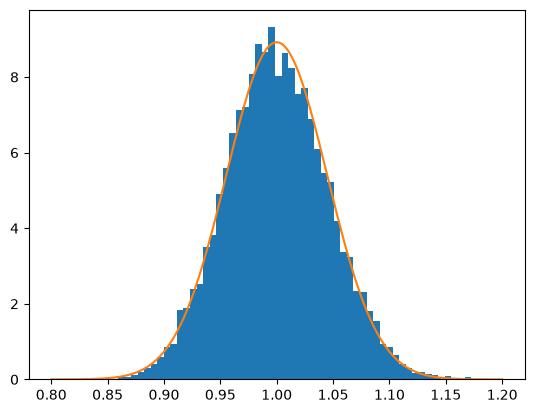

In [6]:
mu, sigma = 1, 1
samples_means = []

for _ in range(10000):
    sample = np.random.exponential(size=500)
    samples_means.append(sample.mean())

xs = np.linspace(0.8, 1.2, 200)

plt.hist(samples_means, bins=60, density=True)
plt.plot(xs, stats.norm.pdf(xs, mu, sigma / np.sqrt(500)))
plt.show()

Выборочные средние легли в нормальный колокол, хотя само распределение скошенное. Так сработала ЦПТ из-за большого размера выборки.

## Задание 3.1

In [7]:
old_cand, old_resp, old_conv = 5000, 155, 0.031
new_cand, new_resp, new_conv = 5000, 170, 0.034

old_se = np.sqrt(old_conv * (1 - old_conv) / old_cand)
new_se = np.sqrt(new_conv * (1 - new_conv) / new_cand)
se_diff = np.sqrt(old_se**2 + new_se**2)
obs_diff = new_conv - old_conv

print(f"{old_se=:.4f}, {new_se=:.4f}")
print(f"{se_diff=:.4f}, {obs_diff=:.4f}")

old_se=0.0025, new_se=0.0026
se_diff=0.0035, obs_diff=0.0030


Ошибка разницы получилась больше самого прироста. Эффект кнопки не доказан, это просто случайный шум.

## Задание 3.2

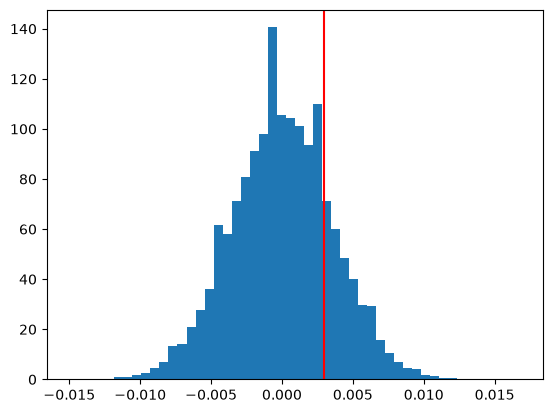

p(diff >= 0.003) = 0.2067
p(|diff| >= 0.003) = 0.4116


In [8]:
p = (old_conv + new_conv) / 2
sims = 100_000

old = np.random.binomial(n=5000, p=p, size=sims) / 5000
new = np.random.binomial(n=5000, p=p, size=sims) / 5000
diff = new - old

plt.hist(diff, bins=50, density=True)
plt.axvline(0.003, color='r')
plt.show()

print(f"p(diff >= 0.003) = {(diff >= 0.003 - 1e-9).mean():.4f}")
print(f"p(|diff| >= 0.003) = {(np.abs(diff) >= 0.003 - 1e-9).mean():.4f}")

Разница в 0.3 п.п. случайно выпадает примерно в каждом пятом тесте. Это обычный шум, эффекта от новой кнопки пока не видно.

## Задание 3.3

In [9]:
data = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

mu = data.mean()
sigma = data.std()

outliers_3sigm = [x for x in data if not (mu - 3*sigma <= x <= mu + 3*sigma)]
perc_99 = np.percentile(data, 99)
outliers_perc = [x for x in data if x >= perc_99]

print(f"3-sigma bound: {round(mu + 3*sigma, 2)}, outliers: {outliers_3sigm}")
print(f"99 percentile: {round(perc_99, 2)}, outliers: {outliers_perc}")

3-sigma bound: 52.21, outliers: []
99 percentile: 48.04, outliers: [np.int64(52)]


Перцентили сработали лучше и сразу нашли выброс. Правило трех сигм не справилось, потому что само число 52 раздуло среднее и ско. Но минус перцентилей в том, что они всегда срезают хвост, даже если выбросов нет.